In [ ]:
!pip install kaggle
!pip install ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 2.8 MB/s eta 0:00:00


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sujaymann/car-number-plate-dataset-yolo-format")

# Display the location where KaggleHub saved the dataset
print("Path to dataset files:", path)

100%|██████████| 203M/203M [00:06<00:00, 34.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/sujaymann/car-number-plate-dataset-yolo-format/versions/3


In [ ]:
import os
# Show the files and folders inside the downloaded dataset
print(os.listdir(path))

['License-Plate-Data']


In [ ]:
import os

# Open the YOLO configuration file.

# Construct the correct path to data.yaml using the 'path' variable.
file_path = os.path.join(path, "License-Plate-Data", "data.yaml")

with open(file_path, "r") as file:
    print(file.read())

names:
  0: license_plate
nc: 1
train: /kaggle/input/car-number-plate-dataset-yolo-format/License-Plate-Data/train
val: /kaggle/input/car-number-plate-dataset-yolo-format/License-Plate-Data/test


In [ ]:

# import yolo
from ultralytics import YOLO

# Load the YOLO8 nano pretrained model
model = YOLO("yolov8n.pt")

# Import cv2 for image and video processing
import cv2


In [ ]:
# Display the files and folders inside the downloaded dataset

for root, dirs, files in os.walk(path):
  print("\nFolder:", root)

  for file in files:
    print("   ", file)


Folder: /root/.cache/kagglehub/datasets/sujaymann/car-number-plate-dataset-yolo-format/versions/3

Folder: /root/.cache/kagglehub/datasets/sujaymann/car-number-plate-dataset-yolo-format/versions/3/License-Plate-Data
    data.yaml

Folder: /root/.cache/kagglehub/datasets/sujaymann/car-number-plate-dataset-yolo-format/versions/3/License-Plate-Data/train

Folder: /root/.cache/kagglehub/datasets/sujaymann/car-number-plate-dataset-yolo-format/versions/3/License-Plate-Data/train/images
    Cars199.png
    Cars301.png
    Cars176.png
    Cars251.png
    Cars61.png
    Cars412.png
    Cars92.png
    Cars398.png
    Cars252.png
    Cars145.png
    Cars26.png
    Cars290.png
    Cars274.png
    Cars180.png
    Cars418.png
    Cars98.png
    Cars310.png
    Cars204.png
    Cars231.png
    Cars187.png
    Cars104.png
    Cars11.png
    Cars429.png
    Cars57.png
    Cars250.png
    Cars170.png
    Cars122.png
    Cars424.png
    Cars175.png
    Cars271.png
    Cars298.png
    Cars115.png
    Cars

In [ ]:
# Create a variable to store the path of data.yaml
yaml_path = None

# Search through all folders inside the dataset
for root, dirs , files in os.walk(path):

    # Check whether data.yaml exists in the current folder
    if "data.yaml" in files:
        yaml_path = os.path.join(root, "data.yaml")
        break

# Display the path of data.yaml
print("data.yaml path:", yaml_path)

data.yaml path: /kaggle/input/car-number-plate-dataset-yolo-format/License-Plate-Data/data.yaml


In [ ]:
results = model.train(
        # Tell YOLO where our dataset configuration is located
        data = yaml_path,
        epochs = 10,
        imgsz = 640,
        batch = 16,
        name="number_plate_detection"


)

Ultralytics 8.4.143 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/car-number-plate-dataset-yolo-format/License-Plate-Data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, n

In [ ]:
print(best_model_path)

None


In [ ]:
import os

# Search for the best trained YOLO model
best_model_path = None

for root, dirs, files in os.walk("/content/runs"):
    if "best.pt" in files:
        best_model_path = os.path.join(root, "best.pt")
        break

print("Best model:", best_model_path)

Best model: /content/runs/detect/number_plate_detection/weights/best.pt


In [ ]:
# Load the best model produced during training
trained_model = YOLO(best_model_path)
print("Trained number plate model loaded successfully!")

Trained number plate model loaded successfully!


In [ ]:
validation_results = trained_model.val()
print("validation results display", validation_results)

Ultralytics 8.4.143 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.5 ms, read: 302.6±114.0 MB/s, size: 622.8 KB)
val: Scanning /kaggle/input/car-number-plate-dataset-yolo-format/License-Plate-Data/test/labels... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 158.5it/s 0.5s
WARNING ⚠️ val: Cache directory /kaggle/input/car-number-plate-dataset-yolo-format/License-Plate-Data/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.2s/it 19.1s
                   all         87         87       0.93      0.805      0.928      0.494
Speed: 1.9ms preprocess, 182.2ms inference, 0.0ms loss, 4.2ms postprocess per image
Results saved to /content/runs/detect/val
validation results display ultralytics.utils.metrics.DetMetrics object with attributes:

ap_cl

In [ ]:
# Create a variable to store a test image
test_image = None
for root, dirs, files in os.walk(path):

  for file in files:
    if file.lower().endswith(('.jpg', '.jpeg', '.png')):
      test_image = os.path.join(root, file)
      break

# Stop outer loop if an image was found
  if test_image is not None:
    break

print("Test image", test_image)


Test image /kaggle/input/car-number-plate-dataset-yolo-format/License-Plate-Data/test/images/Cars393.png



image 1/1 /kaggle/input/car-number-plate-dataset-yolo-format/License-Plate-Data/test/images/Cars393.png: 352x640 1 license_plate, 202.7ms
Speed: 5.3ms preprocess, 202.7ms inference, 1.5ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /content/runs/detect/predict


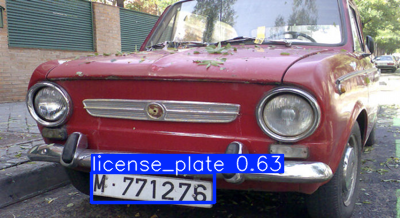

In [ ]:
# Run the trained YOLO model on the test image
results = trained_model.predict(
    source = test_image,
    conf = 0.50,
    save = True

)
results[0].show()

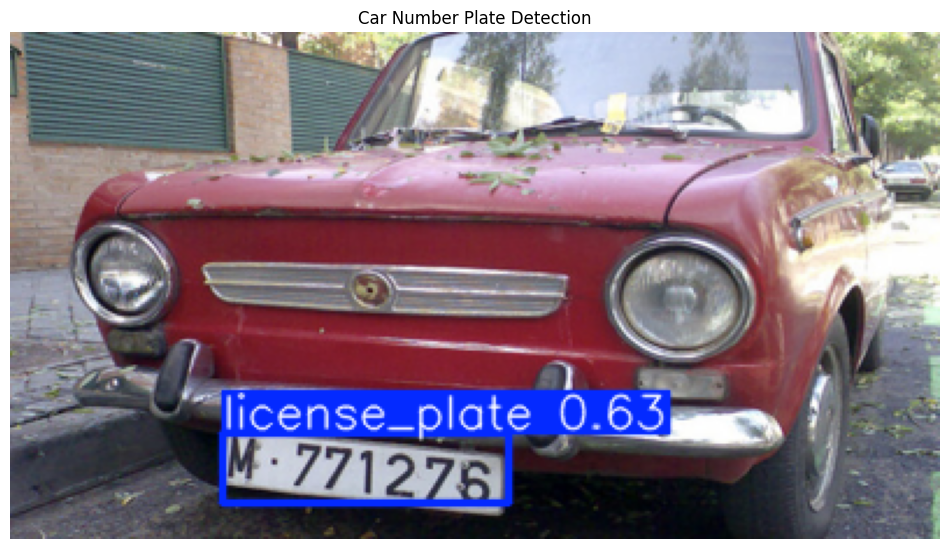

In [ ]:
# Get the image containing YOLO's detection result
detected_image = results[0].plot()

# Convert the image from BGR to RGB
# OpenCV uses BGR while matplotlib uses RGB
detected_image = cv2.cvtColor(
    detected_image,
    cv2.COLOR_BGR2RGB
)
plt.figure(figsize = (12,8))
plt.imshow(detected_image)
plt.title("Car Number Plate Detection")
plt.axis("off")
plt.show()


In [ ]:
# Display all detected bounding boxes
for box in results[0].boxes:
  coordinates = box.xyxy[0].tolist()
  confidence = float(box.conf[0])
  class_id = int(box.cls[0])

  print("Class ID",class_id)
  print("Coordinates",coordinates)
  print("confidence",confidence)

Class ID 0
Coordinates [91.57884216308594, 172.45285034179688, 214.10983276367188, 202.86354064941406]
confidence 0.6290424466133118


In [ ]:
from google.colab import files
upload = files.upload()

Saving car.image.png to car.image (1).png



image 1/1 /content/car.image (1).png: 448x640 1 license_plate, 274.0ms
Speed: 10.4ms preprocess, 274.0ms inference, 3.2ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


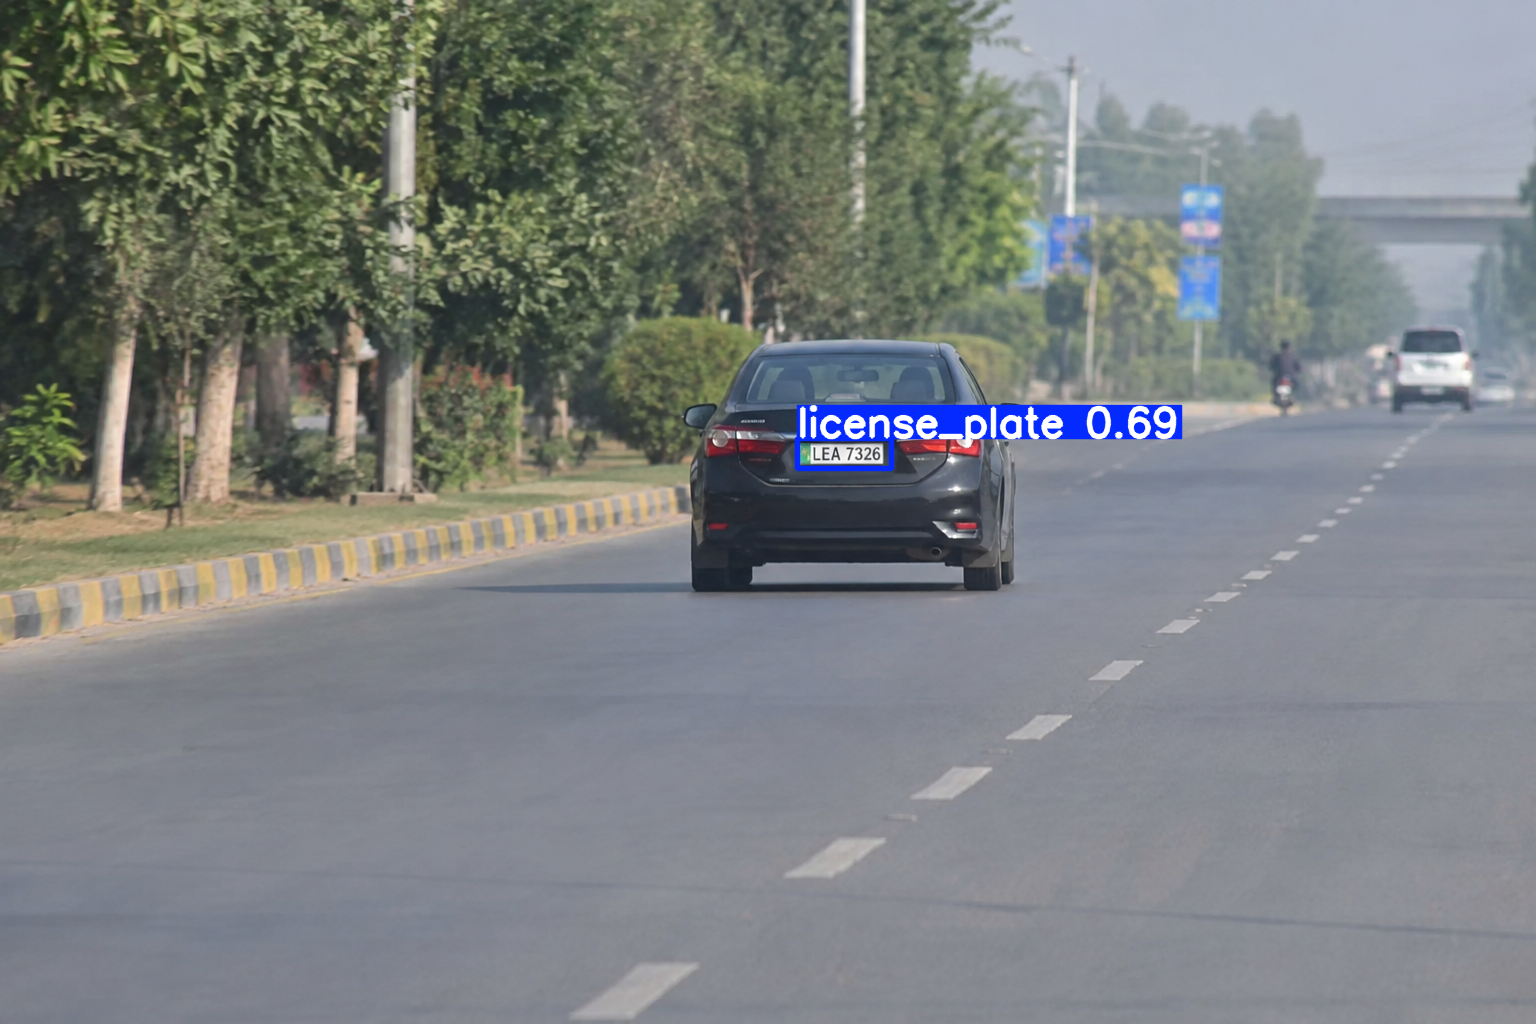

In [ ]:
# Path of your uploaded car image
car_image = "/content/car.image"
results = trained_model.predict(
    source = car_image,
    conf = 0.50,
    save = True
)
results[0].show()